# Задание 5

In [1]:
import re # импортируем
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import csv

In [2]:
class BankAccount: # будет общий родительский класс банковский счёт
    
    init_num = 1000 # стартовый номер
    _OWNER_RE = re.compile(r"[А-ЯЁA-Z][а-яёa-z]* [А-ЯЁA-Z][а-яёa-z]*") # шаблон имени владельца
    account_type = None # тип счёта
    _VALID_OPERATIONS = ("deposit", "withdraw", "transfer_in", "transfer_out", "interest") # эти операции считаем ок
    
    def __init__(self, owner): # создаем экземпляр
        if not isinstance(owner, str) or not self._OWNER_RE.fullmatch(owner): # проверяем корректность имени
            raise ValueError(f"Некорректный владелец: {owner!r}.")
        self.owner = owner
        self.account_number = f"ACC-{BankAccount.init_num}" # генерим ид счёта
        BankAccount.init_num += 1 # увеличиваем для того чтобы все были уникальными
        self.balance_after = 0.0 # нулевой баланс на старте. у нас не будет акций + 1000 за содание счёта
        self.history = [] # тут будем хранить историю
        self.created_at = datetime.now() # когда был создан счёт

    def _updHist(self, operation, amount, status): # добавление записи в историю
        self.history.append({"date": datetime.now(), "operation": operation, "amount": amount, "balance_after": self.balance_after, "status": status})

    def deposit(self, amount): # пополняем счёт
        if not isinstance(amount, (int, float)) or isinstance(amount, bool) or amount <= 0: # проверки что сумма похожа на числои больше 0
            self._updHist("deposit", amount, status=False)
            return False
        self.balance_after += float(amount)
        self._updHist("deposit", float(amount), status=True) # я хочу чтобы статус был bool
        return True # потому что если надо будет вывести только успешные это правильный подход

    def withdraw(self, amount): # снимаем со счёта
        if not isinstance(amount, (int, float)) or isinstance(amount, bool) or amount <= 0: # проверка как в депозите
            self._updHist("withdraw", amount, status=False)
            return False
        if amount > self.balance_after: # проверяем что не вылезли за лимит
            self._updHist("withdraw", float(amount), status=False)
            return False
        self.balance_after -= float(amount)
        self._updHist("withdraw", float(amount), status=True)
        return True

    def operatins_over(self, amount): # ищем все операции на сумму больше чем, с любым статусом
        if not isinstance(amount, (int, float)) or isinstance(amount, bool) or amount <= 0:
            return []
        return [rec for rec in self.history
                if isinstance(rec["amount"], (int, float)) 
                and not isinstance(rec["amount"], bool) 
                and rec["amount"] > amount]

    def import_history(self, records): # вообще интересная тема. Я сначала писал код, потом смотрел данные
        if not isinstance(records, list): # в любом случае на входе ожидаю лист
            return 0, ["ожидался список записей истории"]
        imported, errors = 0, []
        for i, rec in enumerate(records):
            record, reason = self._validate_history_record(rec) # каждую операцию будем проверять отдельно
            if reason:
                errors.append(f"запись {i}: {reason}") # собираем ошибки
            else:
                self.history.append(record) # добавляем операции в истории
                imported += 1
        if imported:
            self.history.sort(key=lambda r: r["date"]) # сортируем для карасоты
        return imported, errors

    def _validate_history_record(self, rec): # проверка одной операции
        if not isinstance(rec, dict):
            return None, "Запись должна быть словарем" # проверка типа данных
        missing = {"date", "account_number", "account_type", "operation", "amount", "balance_after", "status"} - rec.keys() # проверка что есть все поля
        if missing:
            return None, f"нет полей {', '.join(sorted(missing))}"
        date = rec["date"] # проверяем дату на паттерн
        if isinstance(date, str):
            try:
                date = datetime.strptime(date, "%Y-%m-%d %H:%M:%S")
                date = date.isoformat()
            except ValueError:
                return None, f"некорректная дата: {date!r}"
        elif not isinstance(date, datetime):
            return None, f"некорректная дата: {date!r}"
        elif date <= self.created_at:
            return None, f"транзакция проведена раньше открытия счёта: {date!r}" # проверяем что транзакция не раньше открытия счета
        account_number = rec["account_number"] # проверяем номер счёта. 
        if not isinstance(account_number, str) or account_number != self.account_number: # вообще есть большие вопросы - по хорошему надо грузить историю по каждому счёту отдельно
            return None, f"некорректный номер счета: {account_number!r}" # ну типа файл у которого сначала метаданные а потом история, зачем тратить так много места
        account_type = rec["account_type"] # проверяем тип счёта
        if not isinstance(account_type, str) or account_type != self.account_type:
            return None, f"некорректный тип счета: {account_type!r}"
        operation = rec["operation"] # проверяем валидность операции
        if not isinstance(operation, str) or operation not in self._VALID_OPERATIONS:
            return None, f"неизвестный тип операции: {operation!r}"
        if operation == "interest" and self.account_type != "savings":
            return None, "операция возможна только для сберегательного счета"
        amount = rec["amount"] # проверяем сумму и баланс
        if isinstance(amount, str):
            try:
                amount = float(amount)
            except ValueError:
                return None, f"сумма должна быть числом: {amount!r}"
        if not isinstance(amount, (int, float)) or isinstance(amount, bool) or amount <= 0:
            return None, f"сумма операции должна быть числом больше 0: {amount!r}"
        balance_after = rec["balance_after"]
        if isinstance(balance_after, str):
            try:
                balance_after = float(balance_after)
            except ValueError:
                return None, f",баланс должен быть числом: {amount!r}"
        if not isinstance(balance_after, (int, float)) or isinstance(balance_after, bool) or balance_after <= 0:
            return None, f"баланс должен быть числом больше 0: {balance_after!r}"
        status = rec["status"]
        if not (isinstance(status, bool) or isinstance(status, str)): # проверяем статус
            return None, f"некорректный статус: {status!r}"
        if status == "success":
            status = True
        else:
            status = False
        return ({"date": date, "operation": operation, "amount": float(amount), "balance_after": float(balance_after), "status": status}, None)

    def show_history(self): # текстовая история операций
        poindate =  [(self.created_at, "account_creation", 0.0, 0.0)] + [(rec["date"], rec["operation"], rec["amount"], rec["balance_after"]) for rec in self.history]
        text = ""
        for point in poindate:
            text += (f"timestamp: {point[0]}, operation: {point[1]}, amount: {point[2]}, balance_after: {point[3]}\n")
        return text

    def plot_history(self): # история операций на графике
        poindate = [(self.created_at, 0.0)] + [(rec["date"], rec["balance_after"]) for rec in self.history]
        times, balance_afters = zip(*poindate)
        fig, ax = plt.subplots()
        ax.plot(times, balance_afters, marker="o")
        ax.set_xlabel("Время")
        ax.set_ylabel("Баланс")
        ax.set_title(f"Баланс счёта {self.account_number} ({self.owner})")
        date_format = mdates.DateFormatter('%Y-%m-%d %H:%M:%S')
        ax.xaxis.set_major_formatter(date_format)
        fig.autofmt_xdate()
        fig.tight_layout()
        return plt.show(fig)

    def __repr__(self): # красивый вывод на всякий случай
        return (f"BankAccount(id={self.account_number!r}, owner={self.owner!r}, "
                f"balance_after={self.balance_after})")

In [3]:
class CheckingAccount(BankAccount): # расчётный счет
    
    account_type = "checking"

In [4]:
class SavingsAccount(BankAccount): # сберегательный счёт
    
    account_type = "savings"
    _MAX_WITHDRAW_SHARE = 0.5 # максимум сколько можно снять денег

    def __init__(self, owner, interest_rate):
        super().__init__(owner) # проверим процентную стаквку что это хотя бы число, отрицательные ставки тоже бывают, а вдруг счёт валютный
        if not isinstance(interest_rate, (int, float)) or isinstance(interest_rate, bool) or interest_rate < 0:
            raise ValueError(f"Некорректная процентная ставка: {interest_rate!r}")
        self.interest_rate = float(interest_rate)

    def _can_debit(self, amount): # проверка можно ли депнуть весь вклад
        return (super()._can_debit(amount) and amount <= self.balance_after * self._MAX_WITHDRAW_SHARE)

    def accure_interest(self): # начисление процентов
        interest = round(self.balance_after * self.interest_rate / 100, 2)
        self.balance_after += interest
        self._updHist("interest", interest, status=True)
        return interest

    def withdraw(self, amount): # снятие с проверкой
        if (isinstance(amount, (int, float)) and not isinstance(amount, bool) and 0 < amount <= self.balance_after and amount > self.balance_after * self._MAX_WITHDRAW_SHARE):
            self._updHist("withdraw", float(amount), status=False)
            return False
        return super().withdraw(amount)

In [5]:
def transfer(sender, recipient, amount): # перевод. я устал писать комменты, учитывая что дедлайн был 2 дня назад, проверки как и всегда
    if (not isinstance(sender, BankAccount) or not isinstance(recipient, BankAccount) or sender is recipient):
        return False
    if not isinstance(amount, (int, float)) or isinstance(amount, bool) or amount <= 0:
        return False
    if sender.account_type == "savings" and not sender._can_debit(amount):
        sender.UpdHist("transfer_out", float(amount), status=False)
        return False
    sender.balance_after -= float(amount)
    recipient.balance_after += float(amount)
    sender._updHist("transfer_out", float(amount), status=True)
    recipient._updHist("transfer_out", float(amount), status=True)
    return True

In [6]:
a = CheckingAccount("Иван Иванов") # создаем счёт

In [7]:
a.deposit(1000) # деп

True

In [8]:
a.deposit("scdc") # некорректный деп

False

In [9]:
a.withdraw(10000) # пробуем списать слишком много

False

In [10]:
a.deposit(50) # додеп

True

In [11]:
a.deposit(500) # еще додеп

True

In [12]:
a.deposit(300) # и еще додеп

True

In [13]:
a.withdraw(1000) # снятие

True

In [14]:
a.withdraw(500) # и еще спиание

True

In [15]:
a.withdraw(100)

True

In [16]:
print(a.show_history()) # история текстом (да, красивый вывод только через принт, иначе будем наблюдать \n)

timestamp: 2026-10-25 23:03:51.984433, operation: account_creation, amount: 0.0, balance_after: 0.0
timestamp: 2026-10-25 23:03:51.998084, operation: deposit, amount: 1000.0, balance_after: 1000.0
timestamp: 2026-10-25 23:03:52.018852, operation: deposit, amount: scdc, balance_after: 1000.0
timestamp: 2026-10-25 23:03:52.029682, operation: withdraw, amount: 10000.0, balance_after: 1000.0
timestamp: 2026-10-25 23:03:52.050632, operation: deposit, amount: 50.0, balance_after: 1050.0
timestamp: 2026-10-25 23:03:52.072714, operation: deposit, amount: 500.0, balance_after: 1550.0
timestamp: 2026-10-25 23:03:52.089864, operation: deposit, amount: 300.0, balance_after: 1850.0
timestamp: 2026-10-25 23:03:52.110086, operation: withdraw, amount: 1000.0, balance_after: 850.0
timestamp: 2026-10-25 23:03:52.129372, operation: withdraw, amount: 500.0, balance_after: 350.0
timestamp: 2026-10-25 23:03:52.151160, operation: withdraw, amount: 100.0, balance_after: 250.0



In [17]:
g = SavingsAccount("пася вупкин", 10) # ненастоящие имя и фамилия

ValueError: Некорректный владелец: 'пася вупкин'.

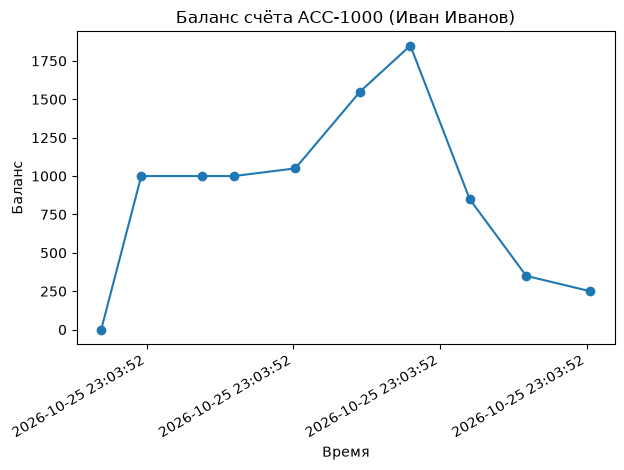

In [18]:
a.plot_history() # история операций на грфаике

In [19]:
b = SavingsAccount("Вася Пупкин", 10) # сберегательный счёт

In [20]:
b.deposit(500.5) # деп

True

In [21]:
b.withdraw(10) # снятие

True

In [22]:
b.withdraw(280) # неуспешное снятие

False

In [23]:
transfer(a, b, 50) # перевод

True

In [24]:
transfer(a, b, 300) # перевод

True

In [25]:
b.accure_interest() # начисление %

84.05

In [26]:
a.operatins_over(200) # все операции больше 200

[{'date': datetime.datetime(2026, 10, 25, 23, 3, 51, 998084),
  'operation': 'deposit',
  'amount': 1000.0,
  'balance_after': 1000.0,
  'status': True},
 {'date': datetime.datetime(2026, 10, 25, 23, 3, 52, 29682),
  'operation': 'withdraw',
  'amount': 10000.0,
  'balance_after': 1000.0,
  'status': False},
 {'date': datetime.datetime(2026, 10, 25, 23, 3, 52, 72714),
  'operation': 'deposit',
  'amount': 500.0,
  'balance_after': 1550.0,
  'status': True},
 {'date': datetime.datetime(2026, 10, 25, 23, 3, 52, 89864),
  'operation': 'deposit',
  'amount': 300.0,
  'balance_after': 1850.0,
  'status': True},
 {'date': datetime.datetime(2026, 10, 25, 23, 3, 52, 110086),
  'operation': 'withdraw',
  'amount': 1000.0,
  'balance_after': 850.0,
  'status': True},
 {'date': datetime.datetime(2026, 10, 25, 23, 3, 52, 129372),
  'operation': 'withdraw',
  'amount': 500.0,
  'balance_after': 350.0,
  'status': True},
 {'date': datetime.datetime(2026, 10, 25, 23, 4, 10, 938377),
  'operation': 't

In [27]:
print(b.show_history()) # смотрим историю по копилке

timestamp: 2026-10-25 23:04:05.798075, operation: account_creation, amount: 0.0, balance_after: 0.0
timestamp: 2026-10-25 23:04:06.623737, operation: deposit, amount: 500.5, balance_after: 500.5
timestamp: 2026-10-25 23:04:07.518208, operation: withdraw, amount: 10.0, balance_after: 490.5
timestamp: 2026-10-25 23:04:08.792628, operation: withdraw, amount: 280.0, balance_after: 490.5
timestamp: 2026-10-25 23:04:10.048289, operation: transfer_out, amount: 50.0, balance_after: 540.5
timestamp: 2026-10-25 23:04:10.938392, operation: transfer_out, amount: 300.0, balance_after: 840.5
timestamp: 2026-10-25 23:04:11.900394, operation: interest, amount: 84.05, balance_after: 924.55



In [28]:
result = [] # читам цсв. 
with open('transactions_dirty.csv', mode="r", encoding="utf-8") as file:
    csv_reader = csv.DictReader(file)
    for row in csv_reader:
        result.append(dict(row))

In [29]:
c = CheckingAccount("Иван Иванов") # файл с историями не предполагает открытие счетов, придётся создать их вручную что нехорошо
d = SavingsAccount("Вася Пупкин", 10) # владельцев оставил тех же
e = CheckingAccount("Иван Иванов") # короче к архитектуре того что планировалось много вопросов, поэтому просто грузану все в каждый счёт
f = SavingsAccount("Вася Пупкин", 10) # к тому же что проверку номера счета я предусмотрел, посмотрев на данные

In [30]:
c.account_number = 'ACC-100001' # а вот и то, почему нельзя грузить историю без создания нового счёта - получается надо все счета держать в инфо о классе
d.account_number = 'ACC-100002' # можно конечно создать там (в классе) список и сверяться с ним, но тогда мы получим приколы при создании новых счетов
e.account_number = 'ACC-100003' # если будут счета ACC-1001 и ACC-1003, то когда мы создадим новый счёт 1002 а потом 1003, мы получим ошибку, что 1003 уже есть
f.account_number = 'ACC-100004'

In [31]:
c.created_at = datetime.fromisoformat("2026-10-01 00:01:45.670910") # руками правим открытие счетов. там есть записи раньше, потестим проверку
d.created_at = datetime.fromisoformat("2026-10-01 00:01:45.670910")
e.created_at = datetime.fromisoformat("2026-10-01 00:01:45.670910")
f.created_at = datetime.fromisoformat("2026-10-01 00:01:45.670910")

In [32]:
c.import_history(result)

(17,
 ["запись 3: некорректная дата: '28/09/2025 22:17'",
  "запись 5: сумма должна быть числом: ''",
  "запись 8: неизвестный тип операции: ''",
  'запись 10: операция возможна только для сберегательного счета',
  "запись 13: некорректная дата: '2025-17-34 12:00:00'",
  "запись 14: некорректная дата: '06/10/2025 22:17'",
  "запись 15: неизвестный тип операции: 'diposit'",
  'запись 16: операция возможна только для сберегательного счета',
  "запись 17: некорректная дата: '2023-16-40 12:00:00'",
  "запись 25: некорректный номер счета: 'ACC-100002'",
  "запись 26: некорректный номер счета: 'ACC-100002'",
  "запись 27: некорректный номер счета: 'ACC-100002'",
  "запись 28: некорректная дата: '2023-22-32 12:00:00'",
  "запись 29: некорректный номер счета: 'ACC-100002'",
  "запись 30: некорректный номер счета: 'ACC-100002'",
  "запись 31: некорректная дата: '04/10/2025 22:17'",
  "запись 32: некорректный номер счета: 'ACC-100002'",
  "запись 33: некорректный номер счета: 'ACC-100002'",
  "з

In [33]:
d.import_history(result)

(18,
 ["запись 0: некорректный номер счета: 'ACC-100001'",
  "запись 1: некорректный номер счета: 'ACC-100001'",
  "запись 2: некорректный номер счета: 'ACC-100001'",
  "запись 3: некорректная дата: '28/09/2025 22:17'",
  "запись 4: некорректный номер счета: 'ACC-100001'",
  "запись 5: некорректный номер счета: 'ACC-100001'",
  "запись 6: некорректный номер счета: 'ACC-100001'",
  "запись 7: некорректный номер счета: 'ACC-100001'",
  "запись 8: некорректный номер счета: 'ACC-100001'",
  "запись 9: некорректный номер счета: 'ACC-100001'",
  "запись 10: некорректный номер счета: 'ACC-100001'",
  "запись 11: некорректный номер счета: 'ACC-100001'",
  "запись 12: некорректный номер счета: 'ACC-100001'",
  "запись 13: некорректная дата: '2025-17-34 12:00:00'",
  "запись 14: некорректная дата: '06/10/2025 22:17'",
  "запись 15: некорректный номер счета: 'ACC-100001'",
  "запись 16: некорректный номер счета: 'ACC-100001'",
  "запись 17: некорректная дата: '2023-16-40 12:00:00'",
  "запись 18:

In [34]:
e.import_history(result)

(13,
 ["запись 0: некорректный номер счета: 'ACC-100001'",
  "запись 1: некорректный номер счета: 'ACC-100001'",
  "запись 2: некорректный номер счета: 'ACC-100001'",
  "запись 3: некорректная дата: '28/09/2025 22:17'",
  "запись 4: некорректный номер счета: 'ACC-100001'",
  "запись 5: некорректный номер счета: 'ACC-100001'",
  "запись 6: некорректный номер счета: 'ACC-100001'",
  "запись 7: некорректный номер счета: 'ACC-100001'",
  "запись 8: некорректный номер счета: 'ACC-100001'",
  "запись 9: некорректный номер счета: 'ACC-100001'",
  "запись 10: некорректный номер счета: 'ACC-100001'",
  "запись 11: некорректный номер счета: 'ACC-100001'",
  "запись 12: некорректный номер счета: 'ACC-100001'",
  "запись 13: некорректная дата: '2025-17-34 12:00:00'",
  "запись 14: некорректная дата: '06/10/2025 22:17'",
  "запись 15: некорректный номер счета: 'ACC-100001'",
  "запись 16: некорректный номер счета: 'ACC-100001'",
  "запись 17: некорректная дата: '2023-16-40 12:00:00'",
  "запись 18:

In [35]:
f.import_history(result)

(22,
 ["запись 0: некорректный номер счета: 'ACC-100001'",
  "запись 1: некорректный номер счета: 'ACC-100001'",
  "запись 2: некорректный номер счета: 'ACC-100001'",
  "запись 3: некорректная дата: '28/09/2025 22:17'",
  "запись 4: некорректный номер счета: 'ACC-100001'",
  "запись 5: некорректный номер счета: 'ACC-100001'",
  "запись 6: некорректный номер счета: 'ACC-100001'",
  "запись 7: некорректный номер счета: 'ACC-100001'",
  "запись 8: некорректный номер счета: 'ACC-100001'",
  "запись 9: некорректный номер счета: 'ACC-100001'",
  "запись 10: некорректный номер счета: 'ACC-100001'",
  "запись 11: некорректный номер счета: 'ACC-100001'",
  "запись 12: некорректный номер счета: 'ACC-100001'",
  "запись 13: некорректная дата: '2025-17-34 12:00:00'",
  "запись 14: некорректная дата: '06/10/2025 22:17'",
  "запись 15: некорректный номер счета: 'ACC-100001'",
  "запись 16: некорректный номер счета: 'ACC-100001'",
  "запись 17: некорректная дата: '2023-16-40 12:00:00'",
  "запись 18:

In [36]:
print(c.show_history()) # ну и посмотреть 1 историю что получилось

timestamp: 2026-10-01 00:01:45.670910, operation: account_creation, amount: 0.0, balance_after: 0.0
timestamp: 2025-09-27T22:17:26, operation: deposit, amount: 921.0, balance_after: 2121.0
timestamp: 2025-09-27T22:17:26, operation: deposit, amount: 607.0, balance_after: 2728.0
timestamp: 2025-09-28T22:17:26, operation: deposit, amount: 488.0, balance_after: 3216.0
timestamp: 2025-09-29T22:17:26, operation: deposit, amount: 880.0, balance_after: 4225.0
timestamp: 2025-10-01T22:17:26, operation: withdraw, amount: 352.0, balance_after: 3687.0
timestamp: 2025-10-01T22:17:26, operation: withdraw, amount: 65.0, balance_after: 3622.0
timestamp: 2025-10-01T22:17:26, operation: withdraw, amount: 245.0, balance_after: 4031.0
timestamp: 2025-10-05T22:17:26, operation: deposit, amount: 327.0, balance_after: 4890.0
timestamp: 2025-10-06T22:17:26, operation: withdraw, amount: 333.0, balance_after: 4557.0
timestamp: 2025-10-12T22:17:26, operation: deposit, amount: 838.0, balance_after: 7292.0
timesta